# Практика: логистическая регрессия — от вероятностей к решениям

Цель: понять сигмоиду, границу решений, вероятности, метрики и компромисс порогов.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay, classification_report)
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Почему не линейная регрессия?
Создадим простой признак и бинарную цель. Линейная модель может предсказывать значения меньше нуля и больше единицы.

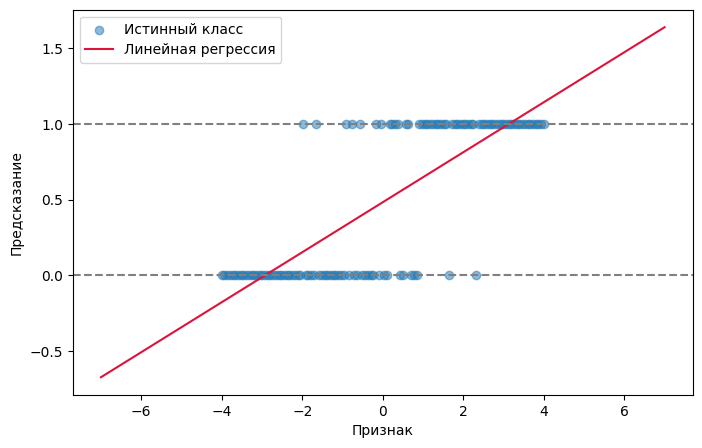

In [2]:
rng = np.random.default_rng(42)
x = np.linspace(-4, 4, 120)
y = (x + rng.normal(0, 1.5, len(x)) > 0).astype(int)
linear = LinearRegression().fit(x.reshape(-1,1), y)
xx = np.linspace(-7, 7, 300)
plt.scatter(x, y, alpha=.5, label="Истинный класс")
plt.plot(xx, linear.predict(xx.reshape(-1,1)), label="Линейная регрессия", color="crimson")
plt.axhline(0, ls="--", color="gray"); plt.axhline(1, ls="--", color="gray")
plt.xlabel("Признак"); plt.ylabel("Предсказание"); plt.legend(); plt.show()

## 2. Сигмоида и вероятность
Логистическая регрессия вычисляет линейную комбинацию признаков, а затем применяет сигмоиду: $p=1/(1+e^{-z})$. При стандартном пороге 0.5 получаем класс 1, если $p\geq 0.5$.

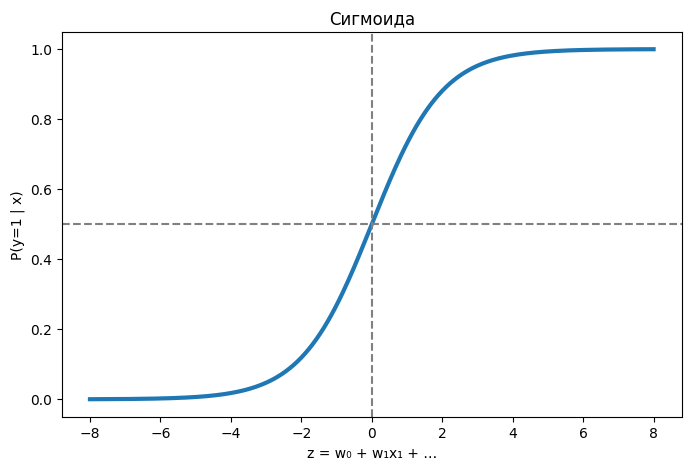

In [3]:
z = np.linspace(-8,8,300)
p = 1/(1+np.exp(-z))
plt.plot(z,p, lw=3); plt.axhline(.5,ls="--",color="gray"); plt.axvline(0,ls="--",color="gray")
plt.xlabel("z = w₀ + w₁x₁ + …"); plt.ylabel("P(y=1 | x)"); plt.title("Сигмоида"); plt.show()

**Вопрос аудитории:** что произойдёт с вероятностью, если z = 0? А если z очень большой?

## 3. Реальная задача: распознавание опухолей
Используем встроенный учебный датасет Wisconsin Breast Cancer. Это демонстрация ML, не медицинский диагностический инструмент. В исходном наборе `target=0` — злокачественная, `target=1` — доброкачественная опухоль. Для удобства переопределим положительный класс как **злокачественная опухоль**.

In [4]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)
print("Размер:", X.shape, "Доля положительного класса:", round(y.mean(),3))
display(X.head())
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.25,stratify=y,random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
model.fit(X_train,y_train)
proba = model.predict_proba(X_test)[:,1]
pred = model.predict(X_test)
display(pd.DataFrame({"Истинный класс":y_test.to_numpy()[:10],"P(злокачественная)":np.round(proba[:10],3),"Прогноз":pred[:10]}))

Размер: (569, 30) Доля положительного класса: 0.373


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,Истинный класс,P(злокачественная),Прогноз
0,1,0.999,1
1,0,0.004,0
2,1,1.000,1
3,0,0.000,0
4,0,0.035,0
5,0,0.004,0
6,0,0.000,0
7,0,0.002,0
8,0,0.007,0
9,0,0.099,0


**Мини-задание:** найдите 3 случая с вероятностью ближе всего к 0.5. Почему эти объекты можно считать неуверенными прогнозами?

In [5]:
uncertain = np.argsort(np.abs(proba-.5))[:3]
display(pd.DataFrame({"Вероятность":proba[uncertain],"Истинный класс":y_test.to_numpy()[uncertain]}))

,Вероятность,Истинный класс
0,0.523800,1
1,0.475960,1
2,0.538258,0


## 4. Граница решений
На синтетических данных с двумя признаками видно, как линейная логистическая регрессия разделяет пространство признаков.

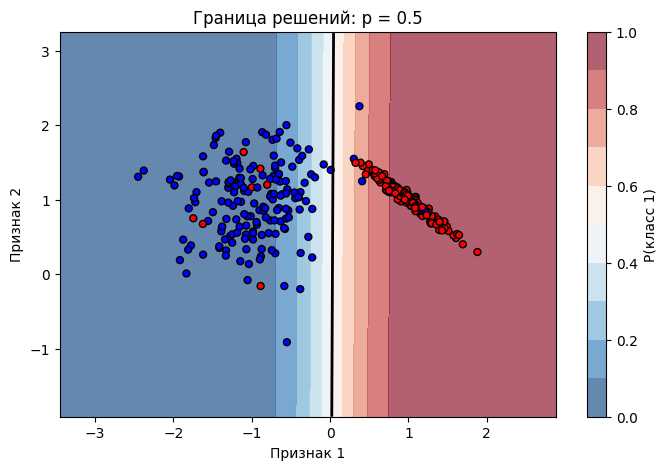

In [6]:
X2,y2 = make_classification(n_samples=350,n_features=2,n_redundant=0,n_informative=2,n_clusters_per_class=1,class_sep=1.0,flip_y=.08,random_state=42)
m2 = make_pipeline(StandardScaler(),LogisticRegression()).fit(X2,y2)
a,b=np.meshgrid(np.linspace(X2[:,0].min()-1,X2[:,0].max()+1,250),np.linspace(X2[:,1].min()-1,X2[:,1].max()+1,250))
grid=np.c_[a.ravel(),b.ravel()]
pp=m2.predict_proba(grid)[:,1].reshape(a.shape)
plt.contourf(a,b,pp,levels=np.linspace(0,1,11),cmap="RdBu_r",alpha=.65)
plt.colorbar(label="P(класс 1)")
plt.contour(a,b,pp,levels=[.5],colors="black",linewidths=2)
plt.scatter(X2[:,0],X2[:,1],c=y2,cmap="bwr",edgecolor="k",s=25)
plt.xlabel("Признак 1");plt.ylabel("Признак 2");plt.title("Граница решений: p = 0.5");plt.show()

**Вопрос:** сможет ли такая модель хорошо разделить два класса в форме концентрических окружностей? Почему?

## 5. Метрики: какие ошибки опаснее?
Положительный класс — злокачественная опухоль. **FN** означает, что положительный случай модель пропустила.

                   precision    recall  f1-score   support

Доброкачественная       0.96      0.99      0.97        90
  Злокачественная       0.98      0.92      0.95        53

         accuracy                           0.97       143
        macro avg       0.97      0.96      0.96       143
     weighted avg       0.97      0.97      0.96       143



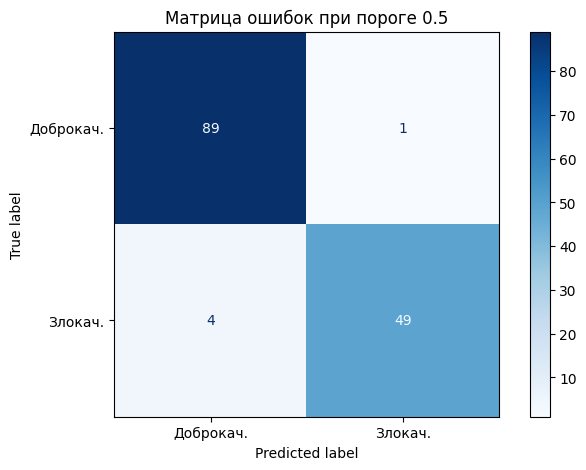

ROC-AUC: 0.996


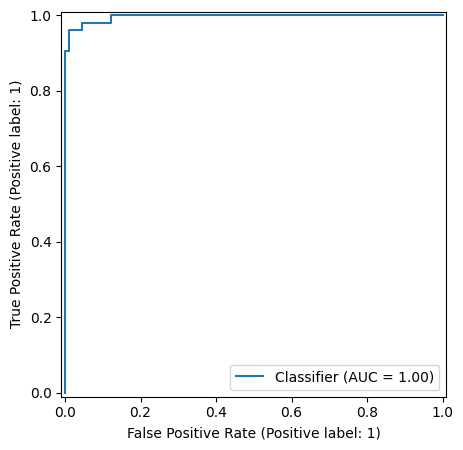

In [7]:
print(classification_report(y_test,pred,target_names=["Доброкачественная","Злокачественная"]))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=["Доброкач.","Злокач."],cmap="Blues")
plt.title("Матрица ошибок при пороге 0.5");plt.show()
print("ROC-AUC:",round(roc_auc_score(y_test,proba),3))
RocCurveDisplay.from_predictions(y_test,proba);plt.show()

## 6. Порог решения — это выбор (15 минут)
Снижение порога часто повышает recall положительного класса, но увеличивает ложноположительные срабатывания.

,Порог,Precision,Recall,F1,FP,FN
0,0.1,0.897,0.981,0.937,6,1
1,0.2,0.944,0.962,0.953,3,2
2,0.3,0.981,0.962,0.971,1,2
3,0.4,0.980,0.943,0.962,1,3
4,0.5,0.980,0.925,0.951,1,4
5,0.6,1.000,0.906,0.950,0,5
6,0.7,1.000,0.906,0.950,0,5
7,0.8,1.000,0.868,0.929,0,7
8,0.9,1.000,0.811,0.896,0,10


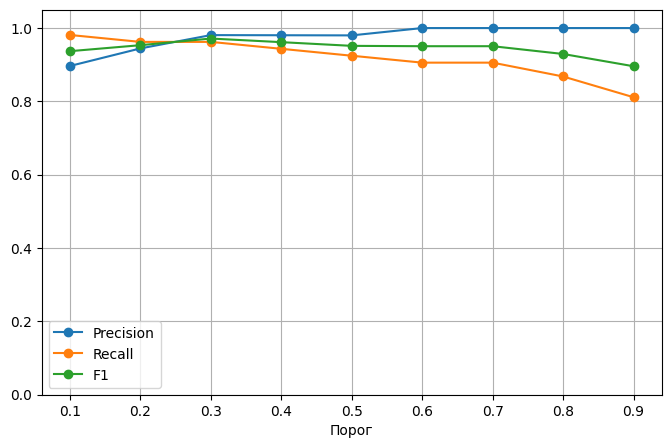

In [8]:
rows=[]
for t in np.arange(.1,.91,.1):
    yp=(proba>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_test,yp,labels=[0,1]).ravel()
    rows.append({"Порог":round(t,1),"Precision":precision_score(y_test,yp,zero_division=0),"Recall":recall_score(y_test,yp),"F1":f1_score(y_test,yp),"FP":fp,"FN":fn})
thresholds=pd.DataFrame(rows)
display(thresholds.round(3))
thresholds.plot(x="Порог",y=["Precision","Recall","F1"],marker="o",ylim=(0,1.05),grid=True);plt.show()

**Задание:** выберите порог с минимальным количеством FN на тестовом наборе. Какую цену приходится платить в FP? В реальном проекте порог выбирают на валидационной выборке, а тестовую оставляют для финальной проверки.

## 7. Масштабирование и регуляризация (15 минут)
Сравним пайплайны с масштабированием и без него, затем изменим `C`: меньшее C означает более сильную L2-регуляризацию.

In [9]:
experiments=[]
for scale in [False,True]:
    for C in [.01,1,100]:
        m=make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=5000)) if scale else LogisticRegression(C=C,max_iter=5000)
        m.fit(X_train,y_train)
        score=m.predict_proba(X_test)[:,1]
        experiments.append({"Масштабирование":scale,"C":C,"ROC-AUC":roc_auc_score(y_test,score),"F1":f1_score(y_test,score>=.5)})
display(pd.DataFrame(experiments).round(3))

C:\Users\Zalina\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Масштабирование,C,ROC-AUC,F1
0,False,0.01,0.995,0.920
1,False,1.00,0.995,0.920
2,False,100.00,0.995,0.922
3,True,0.01,0.999,0.929
4,True,1.00,0.996,0.951
5,True,100.00,0.976,0.911


## Итоги и проверка понимания
1. Почему логистическая регрессия называется регрессией, хотя решает задачу классификации?
2. Чем отличаются `predict` и `predict_proba`?
3. Что произойдёт при уменьшении порога с 0.5 до 0.2?
4. Почему accuracy иногда вводит в заблуждение?
5. Для чего нужен `StandardScaler` и как связан `C` с регуляризацией?

**Дополнительный эксперимент:** создайте несбалансированную выборку (`weights=[0.95,0.05]` в `make_classification`) и сравните accuracy и recall.

**Методическое замечание:** показатели на тестовой выборке в этом ноутбуке служат иллюстрацией. Для честного подбора гиперпараметров и порога нужна отдельная валидация или кросс-валидация.